# Lab session 1

**Vanessa Gómez Verdejo,  Pablo Martínez Olmos, Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />


# Age Prediction from Face Images with PyTorch

Welcome to this hands-on lab! In this notebook, you will build and train deep learning models using PyTorch to solve a regression task: predicting a person’s age from facial images using the UTKFace dataset.

We’ll guide you through the process of building simple and advanced models, using modern deep learning practices, and integrating tools like PyTorch Lightning and MLflow to streamline development and monitor results.

**General Objective**: Familiarize yourself with PyTorch by constructing and training models for a regression task (age prediction from facial images), using simple architectures (MLP and CNN), data augmentation, and transfer learning.

Import libraries

In [1]:
import torch
from PIL import Image
from torch.utils.data import Dataset, random_split, DataLoader, TensorDataset
import numpy as np
import pytorch_lightning as pl
from torch.nn import MSELoss
from torch.nn import L1Loss
import matplotlib.pyplot as plt
import pandas as pd
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from torchinfo import summary
from IPython.display import clear_output

IMAGES_PATH = '../Dataset/full_UTK_64x64.pt'
AGES_PATH = '../Dataset/full_ages_UTK.pt'

## 1. Dataset Setup

We will use the **UTKFace dataset**, a large collection of face images labeled with age (and other attributes).

The original UTKFace dataset can be downloaded from [Kaggle](https://www.kaggle.com/datasets/moritzm00/utkface-cropped?resource=download). However, to simplify preprocessing and reduce loading times, we provide two preprocessed versions of the dataset in the form of PyTorch tensors:

* The image tensors are stored in the file `full_UTK_64x64.pt`  containing all images at resolution 64x64.  To simplify and accelerate your experimentation.
* The corresponding age labels are provided in `full_ages_UTK.pt`, which align one-to-one with the image tensors.

The data is stored as preprocessed PyTorch tensors in `.pt` files. You won’t have to deal with raw image loading. Instead, your first task is to implement a custom PyTorch `Dataset` and prepare the corresponding **DataLoaders** for training, validation, and testing.

This class has to:
- Load preprocessed tensors.
- Scale pixel values to the [0, 1] range.
- Randomly split the dataset into **50% training**, **25% validation**, and **25% test**.
- Return images and corresponding ages as `float32`.

Once you instantiate the dataset, make sure to build the corresponding PyTorch **DataLoaders**, with appropriate batch sizes (e.g., 32 or 64) and shuffling for the training set.

Next, it's important to explore and visualize the dataset to gain some intuition about the task. Start by displaying a few sample images along with their corresponding ages to get a sense of the data quality and variability. Then, plot the distribution of ages across the dataset to understand whether it is balanced or skewed toward certain age ranges.


Custom dataset

In [2]:

class CustomImageDataset(Dataset):
    def __init__(self, images_path, ages_path):

        self.images = torch.load(images_path).to(torch.float32)/255
        self.ages = torch.load(ages_path).to(torch.float32)
       
   
    def __len__(self):
        return self.images.shape[0]

    def __getitem__(self, idx):
        return self.images[idx], self.ages[idx]
       


We read data 

Age is 46.0


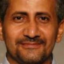

In [3]:

data = CustomImageDataset(IMAGES_PATH, AGES_PATH)

index = np.random.randint(len(data))

image, age = data[index]

print("Age is", age.item())

img = image.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
img = (img * 255).clip(0, 255).astype(np.uint8)

display(Image.fromarray(img))

We split the data in train, validation and test

In [4]:
n_total = len(data)

torch.manual_seed(1234)
pl.seed_everything(4567)

n_train = int(0.5 * n_total)
n_val = int(0.25 * n_total)
n_test = n_total - n_train - n_val

train_data, val_data, test_data = random_split(
    data,
    [n_train, n_val, n_test]
)

Seed set to 4567


## 2. Building a Simple MLP

With the data ready, your next task is to design a **Multilayer Perceptron (MLP)**. The architecture will serve as a baseline for later models. Here is the basic structure:

- Input: Flattened image tensor (e.g., for 64×64 images → 3 × 64 × 64 = 12288 input units)
- Hidden layer: 128 neurons, followed by a **ReLU** activation
- Output layer: A single neuron predicting a continuous value (the age)

Use `nn.MSELoss` as your training loss, and also compute the validation MSE (Mean Square Error) during during the training.

Wrap this model inside a `LightningModule`, and use the `LightningTrainer` to handle training loops. Don’t forget to implement:
- `training_step`, `validation_step`, and optionally `test_step`
- Optimizer configuration (e.g., Adam with learning rate 1e-3)

Train the model for **50 epochs** and log all key metrics using **MLflow**; for example, you can log training/validation loss. You can structure your logging using the built-in logger from PyTorch Lightning.

Later,  and plot some example predictions vs. ground truth.


After training, visualize and interpret your results:
- Analyze the training and validation loss curves.
- Compute training and test MSE and MAE (Mean Absolute Error) for interpretability
- Compare predicted vs. actual ages on a few test samples.
- Analyze how the model performs across different age ranges (e.g., is it worse for children or elderly faces?).


In [5]:
class SimpleMLP(torch.nn.Module):
    def __init__(self, num_features):
        super().__init__()

        self.all_layers = torch.nn.Sequential(
            # 1st hidden layer
            torch.nn.Linear(num_features, 128),
            torch.nn.ReLU(),
            # output layer
            torch.nn.Linear(128, 1),
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        y = self.all_layers(x)
        # question: torch.exp() can be used if we want to apply the exponential function to the output
        return y

In [6]:
class LitGenericModel(pl.LightningModule):
    def __init__(self, model, loss, accuracy ,lr=1e-3):
        super().__init__()
        self.save_hyperparameters(ignore=['model', 'loss', 'accuracy'])  # logs hyperparameters automatically

        self.model = model
        self.loss = loss
        self.accuracy = accuracy

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch):
        xs, ys = batch
        ys_estimate = self(xs)
        ys_estimate = ys_estimate.squeeze(1)
        loss = self.loss(ys_estimate, ys)
        acc = self.accuracy(ys_estimate, ys)
  
        return loss, acc, ys_estimate, ys

    def training_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.train', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('acc.train', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.valid', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('acc.valid', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def test_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.test', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('acc.test', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

In [7]:
num_epochs = 50

model = SimpleMLP(3*64*64)

lit_model = LitGenericModel(model=model, loss=MSELoss(), accuracy=L1Loss())

logger = CSVLogger(
    save_dir="lightning_logs",
    name="MLP",
    version="fixed"
)

trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=1,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger)

train_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_data, batch_size=len(val_data), shuffle=False)
test_data_loader = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory lightning_logs/MLP/fixed exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory lightning_logs/MLP/fix

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 49: 100%|██████████| 186/186 [00:00<00:00, 348.80it/s, v_num=ixed]

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 49: 100%|██████████| 186/186 [00:00<00:00, 340.67it/s, v_num=ixed]


In [9]:
def evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader):

    train_metrics = trainer.validate(lit_model, dataloaders=train_data_loader, verbose=False)
    val_metrics  = trainer.validate(lit_model, dataloaders=valid_data_loader, verbose=False)   # logs 'acc.val', 'loss.val'
    test_metrics = trainer.test(lit_model,    dataloaders=test_data_loader, verbose=False)  # logs 'acc.test', 'loss.test'

    train_loss = train_metrics[0].get('loss.valid')
    val_loss = val_metrics[0].get('loss.valid')
    test_loss = test_metrics[0].get('loss.test')

    train_acc = train_metrics[0].get('acc.valid')
    val_acc = val_metrics[0].get('acc.valid')
    test_acc = test_metrics[0].get('acc.test')

    metrics_df = pd.DataFrame(columns = ['loss', 'accuracy'], index=['train', 'val', 'test'])
    metrics_df.loc['train'] = [train_loss, train_acc]
    metrics_df.loc['val'] = [val_loss, val_acc]
    metrics_df.loc['test'] = [test_loss, test_acc]

    clear_output(wait=False)

    return metrics_df



In [10]:
metrics_df =evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

metrics_df

,loss,accuracy
train,168.452621,10.037458
val,203.291412,10.883051
test,206.904739,10.915679


In [11]:
def display_random_test_samples(test_data, lit_model, num_samples=10):
    lit_model.eval()

    for i in range(num_samples):  # Display random test samples
        index = np.random.randint(test_data.__len__())

        pred = lit_model(test_data[index][0].unsqueeze(0))

        print(pred)

        image, age = test_data[index]

        print("Age is", age.item())

        img = image.numpy().transpose(1, 2, 0)   # tensor -> numpy, [C,H,W] -> [H,W,C]
        img = (img * 255).clip(0, 255).astype(np.uint8)

        display(Image.fromarray(img))



tensor([[43.2946]], grad_fn=<AddmmBackward0>)
Age is 35.0


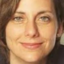

tensor([[41.7795]], grad_fn=<AddmmBackward0>)
Age is 43.0


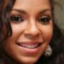

tensor([[49.2524]], grad_fn=<AddmmBackward0>)
Age is 38.0


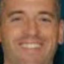

tensor([[49.1624]], grad_fn=<AddmmBackward0>)
Age is 24.0


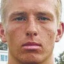

tensor([[44.7496]], grad_fn=<AddmmBackward0>)
Age is 53.0


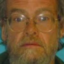

tensor([[8.6514]], grad_fn=<AddmmBackward0>)
Age is 3.0


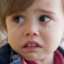

tensor([[34.4604]], grad_fn=<AddmmBackward0>)
Age is 85.0


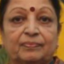

tensor([[58.4619]], grad_fn=<AddmmBackward0>)
Age is 45.0


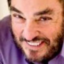

tensor([[56.0004]], grad_fn=<AddmmBackward0>)
Age is 36.0


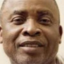

tensor([[76.4453]], grad_fn=<AddmmBackward0>)
Age is 38.0


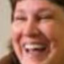

In [12]:
display_random_test_samples(test_data, lit_model)

In [13]:
def plot_training_metrics(metrics_csv_path):
    train_metrics = pd.read_csv(metrics_csv_path)

    f, ax = plt.subplots(2,1, figsize=(10,8))
    train_epoch_metrics = train_metrics[["epoch", "acc.train"]].dropna()
    valid_epoch_metrics = train_metrics[["epoch", "acc.valid"]].dropna()

    ax[0].plot(train_epoch_metrics["epoch"], train_epoch_metrics["acc.train"], marker="o", label="Train MAE")
    ax[0].plot(valid_epoch_metrics["epoch"], valid_epoch_metrics["acc.valid"], marker="o", label="Validation MAE")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("MAE")
    ax[0].legend()
    ax[0].grid(True)
    train_loss_metrics = train_metrics[["epoch", "loss.train"]].dropna()
    valid_loss_metrics = train_metrics[["epoch", "loss.valid"]].dropna()

    ax[1].plot(train_loss_metrics["epoch"], train_loss_metrics["loss.train"], marker="o", label="Train Loss")
    ax[1].plot(valid_loss_metrics["epoch"], valid_loss_metrics["loss.valid"], marker="o", label="Validation Loss")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    ax[1].legend()
    ax[1].grid(True)

    plt.show()



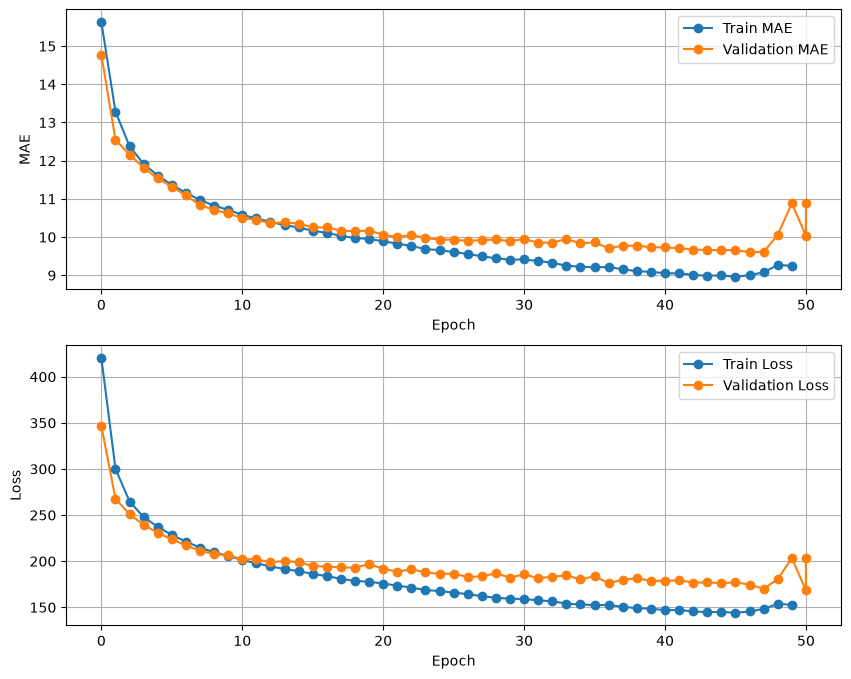

In [14]:
plot_training_metrics("lightning_logs/MLP/fixed/metrics.csv")


In [15]:
def evaluate_age_ranges(data, trainer, lit_model):

    max_age = np.ceil(data[0:][1].numpy().max()/10)*10
    print(max_age)

    age_ranges = np.arange(0, max_age + 5 , 5)

    prop = []
    acc = []

    images, ages = data[0:]

    for i in range(len(age_ranges) - 1):
        mask = (ages >= age_ranges[i]) & (ages < age_ranges[i+1])

        data_in_range = TensorDataset(images[mask], ages[mask])
        data_loader = DataLoader(data_in_range, batch_size=32, shuffle=False)

        metrics = trainer.validate(lit_model, dataloaders=data_loader)

        prop.append(len(data_in_range) / len(data))
        acc.append(metrics[0].get("acc.valid"))

    fig, ax1 = plt.subplots()
    color = 'tab:blue'
    ax1.set_xlabel('Age Range')
    ax1.set_ylabel('Accuracy', color=color)
    ax1.plot(age_ranges[:-1]+2.5, acc, color=color)
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Proportion', color=color)
    ax2.bar(age_ranges[:-1]+2.5, prop, color=color, alpha=0.3, width=4.5)
    ax2.tick_params(axis='y', labelcolor=color)

    fig.tight_layout()
    plt.title('Accuracy and Proportion by Age Range')
    plt.show()

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


120.0
Validation DataLoader 0: 100%|██████████| 18/18 [00:00<00:00, 371.26it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
     Validate metric           DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        acc.valid            12.01347541809082
       loss.valid            256.9718933105469
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Validation DataLoader 0: 100%|██████████| 7/7 [00:00<00:00, 398.15it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
     Validate metric           DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        acc.valid           14.942899703979492
       loss.va

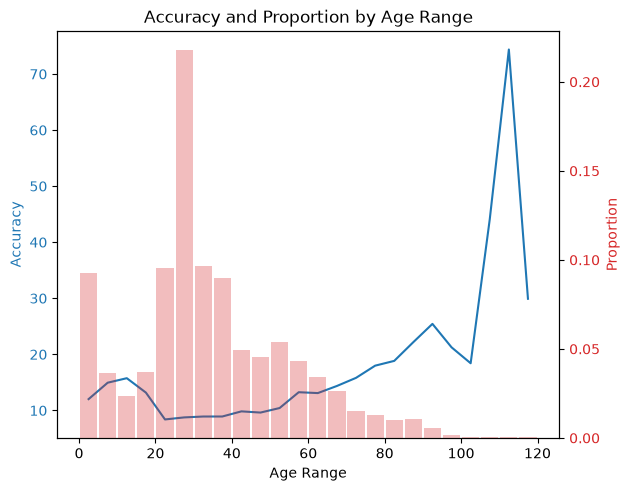

In [16]:
evaluate_age_ranges(test_data, trainer, lit_model)



## 3. Convolutional Neural Networks (CNNs) for Age Prediction

In this part, you’ll move beyond fully connected layers and explore the power of **Convolutional Neural Networks (CNNs)** for image-based regression. CNNs are particularly well-suited to visual data, as they can exploit spatial hierarchies and local patterns more effectively than MLPs.

Your goal is to implement a simple CNN-based regressor and evaluate whether it outperforms the MLP from Part 2.

Thus, you will implement a CNN with the following structure:
- Two convolutional layers with 3×3 kernels and ReLU activation.
- 2×2 max pooling after each convolution to reduce spatial dimensions.
- A fully connected layer with 128 neurons.
- A final output layer predicting a single real value (age).

As before, implement the model using **PyTorch Lightning**, wrapping the architecture into a `LightningModule`. Train the model using the same loss function (`MSELoss`).

Once training is complete, perform a thorough evaluation of the CNN:
- Plot training and validation losses over time using **MLflow**. Note that you can now compare this run directly against your MLP results. Did it converge faster?
- Compute train and test MSE and MAE. Did the CNN achieve lower MAE or MSE than the MLP? Does it generalize better to unseen data?
- Compare again predicted vs. actual ages on a few test samples and analyze how the model performs across different age ranges.



In [17]:
class SimpleCNN(torch.nn.Module):
    def __init__(self):
        super().__init__()

        self.all_layers = torch.nn.Sequential(
            # 1st cnn layer
            torch.nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Flatten(),
            torch.nn.LazyLinear(128),
            torch.nn.ReLU(),
            torch.nn.Linear(128,1)
        )

    def forward(self, x):
        y = self.all_layers(x)
        # question: torch.exp() can be used if we want to apply the exponential function to the output
        return y

In [18]:
model = SimpleCNN()

summary(model, input_size=(10000,
     3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [10000, 1]                --
├─Sequential: 1-1                        [10000, 1]                --
│    └─Conv2d: 2-1                       [10000, 16, 64, 64]       448
│    └─ReLU: 2-2                         [10000, 16, 64, 64]       --
│    └─MaxPool2d: 2-3                    [10000, 16, 32, 32]       --
│    └─Conv2d: 2-4                       [10000, 32, 32, 32]       4,640
│    └─ReLU: 2-5                         [10000, 32, 32, 32]       --
│    └─MaxPool2d: 2-6                    [10000, 32, 16, 16]       --
│    └─Flatten: 2-7                      [10000, 8192]             --
│    └─Linear: 2-8                       [10000, 128]              1,048,704
│    └─ReLU: 2-9                         [10000, 128]              --
│    └─Linear: 2-10                      [10000, 1]                129
Total params: 1,053,921
Trainable params: 1,053,921
Non-trainable params:

In [19]:
num_epochs = 50

model = SimpleCNN()

lit_model = LitGenericModel(model=model, loss=MSELoss(), accuracy=L1Loss())

logger = CSVLogger(
    save_dir="lightning_logs",
    name="SimpleCNN",
    version="fixed"
)

trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=1,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger)

train_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_data, batch_size=len(val_data), shuffle=False)
test_data_loader = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory lightning_logs/SimpleCNN/fixed exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory lightning_logs/S

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 49: 100%|██████████| 186/186 [00:00<00:00, 208.78it/s, v_num=ixed]

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 49: 100%|██████████| 186/186 [00:00<00:00, 205.84it/s, v_num=ixed]


In [20]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,accuracy
train,69.244797,6.266521
val,161.394272,9.19731
test,166.728333,9.388099


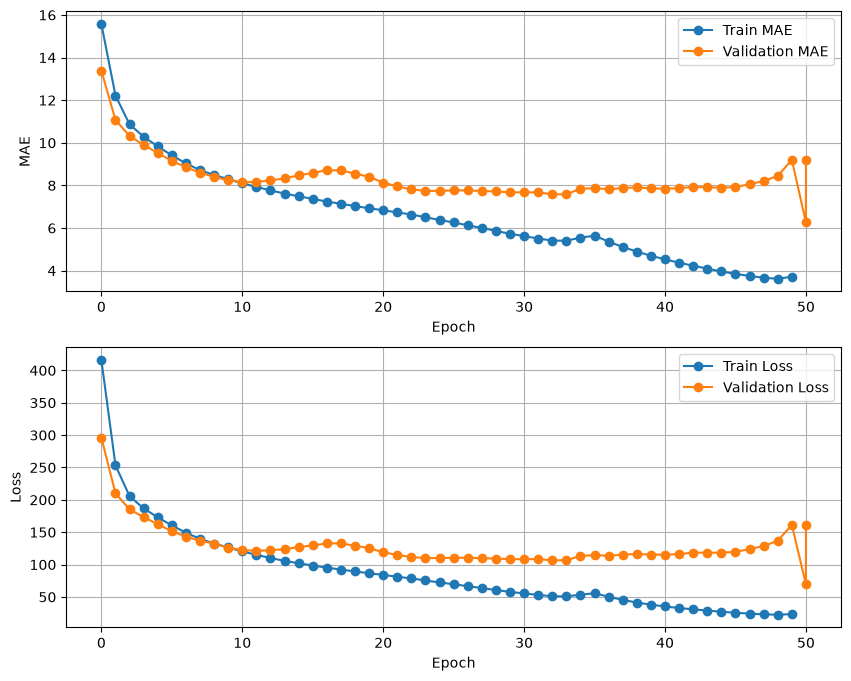

In [21]:
plot_training_metrics("lightning_logs/SimpleCNN/fixed/metrics.csv")

/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/lolillosky/PHD_Projects/GenerativeDeepLearningCourse/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


120.0
Validation DataLoader 0: 100%|██████████| 18/18 [00:00<00:00, 205.17it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
     Validate metric           DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        acc.valid            5.918692588806152
       loss.valid            79.00244903564453
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Validation DataLoader 0: 100%|██████████| 7/7 [00:00<00:00, 235.10it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
     Validate metric           DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        acc.valid            8.73261547088623
       loss.val

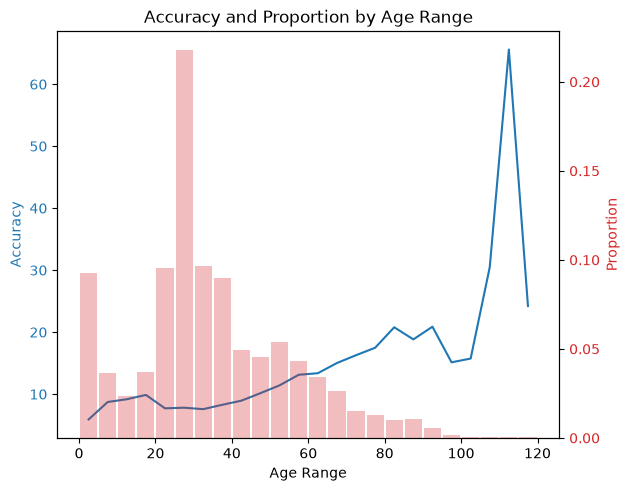

In [22]:
evaluate_age_ranges(test_data, trainer, lit_model)

tensor([[0.2884]], grad_fn=<AddmmBackward0>)
Age is 1.0


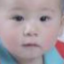

tensor([[48.6949]], grad_fn=<AddmmBackward0>)
Age is 41.0


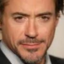

tensor([[36.7766]], grad_fn=<AddmmBackward0>)
Age is 35.0


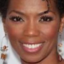

tensor([[36.4462]], grad_fn=<AddmmBackward0>)
Age is 35.0


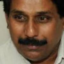

tensor([[58.2543]], grad_fn=<AddmmBackward0>)
Age is 45.0


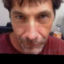

tensor([[27.6260]], grad_fn=<AddmmBackward0>)
Age is 23.0


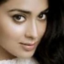

tensor([[31.8029]], grad_fn=<AddmmBackward0>)
Age is 35.0


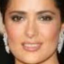

tensor([[54.7667]], grad_fn=<AddmmBackward0>)
Age is 74.0


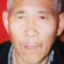

tensor([[36.6162]], grad_fn=<AddmmBackward0>)
Age is 33.0


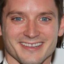

tensor([[44.3339]], grad_fn=<AddmmBackward0>)
Age is 24.0


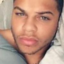

In [23]:
display_random_test_samples(test_data, lit_model)

## 4. Mitigating Overfitting in CNNs

In the previous section, you trained a CNN model for age prediction and likely observed signs of overfitting. This is a common issue when working with deeper models like CNNs, especially when data is limited.

To fully take advantage of the representational power of CNNs, you’ll now implement regularization strategies that help prevent overfitting and improve generalization.

In this part, your goal is to experiment with techniques that promote more robust learning:

You will extend your CNN architecture to include:

1.  **Dropout**: Randomly deactivates a fraction of neurons during training, reducing over-reliance on specific features. Include a dropout layer with a probaility of 0.25 before the final output (you can explore other probability values).

2.  **Batch Normalization**: Normalizes intermediate activations and helps stabilize learning, enabling faster convergence and acting as a form of regularization. Include BatchNorm layers after each convolution.

3. **Early Stopping**: Monitors validation loss and halts training when performance no longer improves, avoiding unnecessary overfitting. You can stop the training if the valiadtion error does not improve after 3 epochs.

As before, implement your model using PyTorch Lightning, and log all metrics and training curves with MLflow.

Once you’ve trained your regularized CNN, analyze its behavior and compare it to the version without regularization:

* Compare the training and validation loss curves for each individual strategy as well as for the combination of all strategies. Did overfitting reduce? Did the training process become more stable?

* Evaluate performance using MSE and MAE on the train, validation, and test sets.

* Discuss which regularization techniques were most effective.

In [24]:
class SimpleCNN_batchnorm_dropout(torch.nn.Module):
    def __init__(self, batch_norm=False, dropout=0.0):
        super().__init__()

        self.all_layers = torch.nn.Sequential(
            # 1st cnn layer
            torch.nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(16) if batch_norm else torch.nn.Identity(),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Dropout2d(dropout),
            torch.nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(32) if batch_norm else torch.nn.Identity(),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            torch.nn.Dropout2d(dropout),
            torch.nn.Flatten(),
            torch.nn.LazyLinear(128),
            torch.nn.BatchNorm1d(128) if batch_norm else torch.nn.Identity(),
            torch.nn.ReLU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(128,1)
        )

    def forward(self, x):
        y = self.all_layers(x)
        return y

In [25]:
def train_simple_cnn_early_stopping_batchnorm_dropout(early_stopping = False, batch_norm=False, dropout=0.0):

    num_epochs = 50

    model = SimpleCNN_batchnorm_dropout(batch_norm=batch_norm, dropout=dropout)

    lit_model = LitGenericModel(model=model, loss=MSELoss(), accuracy=L1Loss())

    logger = CSVLogger(
        save_dir="lightning_logs",
        name="CNN" + ("_BN" if batch_norm else "") + ("_DO" + str(dropout) if dropout > 0 else "") + ("_ES" if early_stopping else ""),
        version="fixed"
    )

    callbacks = []
    if early_stopping:
        callbacks.append(EarlyStopping(monitor="loss.valid", patience=3, mode="min"))

    trainer =  pl.Trainer(max_epochs=num_epochs,
        log_every_n_steps=1,
        deterministic=True,     # aim for reproducibility where possible
        accelerator="auto",     # use GPU if available
        devices="auto",
        logger=logger,
        callbacks=callbacks)

    train_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)
    valid_data_loader = DataLoader(val_data, batch_size=len(val_data), shuffle=False)
    test_data_loader = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

    trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)

    clear_output(wait=False)
    
    return trainer, lit_model


In [26]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(True, False, 0.0)

In [27]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,accuracy
train,85.281479,7.001596
val,113.837219,7.93663
test,121.063965,8.160433


In [28]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(False, True, 0.0)

In [29]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,accuracy
train,24.55982,3.637864
val,118.949188,7.948197
test,128.293411,8.1009


In [30]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(True, True, 0.0)

In [31]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,accuracy
train,68.461754,6.37008
val,136.064728,8.914634
test,141.003479,8.990462


In [32]:
dropout_probs = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]

metrics = [] 

for dropout_prob in dropout_probs:
    trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(False, False, dropout_prob)
    print(f"Trained with dropout probability: {dropout_prob}. Results:")
    metrics_df = evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)
    metrics.append(metrics_df)
  
for m in metrics:
    display(m)


,loss,accuracy
train,50.082603,5.355361
val,125.617874,8.009756
test,129.394821,8.054622


,loss,accuracy
train,43.644825,4.93781
val,111.528267,7.506203
test,118.078789,7.62948


,loss,accuracy
train,48.642822,5.218564
val,114.2855,7.616105
test,119.37989,7.635832


,loss,accuracy
train,49.488255,5.280774
val,107.262131,7.449709
test,117.659691,7.617869


,loss,accuracy
train,61.870434,5.848601
val,111.96431,7.595103
test,121.218964,7.684379


,loss,accuracy
train,96.661995,7.332622
val,134.824921,8.372014
test,144.983612,8.486343


,loss,accuracy
train,76.142578,6.3754
val,112.654404,7.624355
test,121.879997,7.742048


In [33]:
trainer, lit_model = train_simple_cnn_early_stopping_batchnorm_dropout(True, True, 0.3)

In [35]:
evaluate_model(trainer, lit_model, train_data_loader, valid_data_loader, test_data_loader)

,loss,accuracy
train,95.120728,7.238314
val,122.827896,8.193557
test,133.185806,8.33213


## 5. Data Augmentation to Improve Generalization

In this section, you will explore **Data Augmentation** as a technique to reduce overfitting, especially when training deep models on relatively small datasets. Data Augmentation artificially increases the diversity of the training data by applying random transformations to the original images. This helps the model become more robust by exposing it to a wider variety of visual scenarios during training.

Common image transformations include:

- **Rotation**: Randomly rotating the image by a few degrees.
- **Horizontal Flip**: Mirroring the image to simulate left/right variation.
- **Brightness and Contrast Adjustment**: Introducing lighting variability.
- **Random Resized Crop**: Cropping random portions of the image and resizing them, encouraging the model to focus on multiple parts of the object.

These augmentations help the model generalize better by reducing its reliance on specific patterns or image positions.

We will use the `torchvision.transforms.v2` module to apply these transformations. A typical transformation pipeline might look like this:

```python
import torchvision.transforms.v2 as v2

transform = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(20),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.RandomResizedCrop(64, scale=(0.8, 1.0)),
])
```

You should now update your custom dataset class to apply these transformations to the training data only. Then, define new DataLoaders for training, validation, and test sets accordingly.

**Use the best model from the previous section** (i.e., your CNN including the best regularization strategies like dropout, batch normalization, and early stopping) and train it again using the augmented data. Compare its performance to the previous version trained without augmentation.

**Discussion**: Try different combinations of transformations and vary their parameters (e.g., rotation angle, brightness factor, scale range). Discuss which ones seem most appropriate for this task and why. Are there any transformations that seem to harm performance or introduce unrealistic samples?



## 6. Data Augmentation for Balancing Age Ranges

As you likely noticed, the dataset may be imbalanced across different age ranges, which could lead to your model performing worse on underrepresented groups (e.g., older individuals). To help balance the data, we will use data augmentation to generate additional images for underrepresented age ranges.

**Strategy for Balancing the Dataset**:

- Analyze underrepresented age groups: First, you need to check the distribution of ages across the dataset to identify which age groups are underrepresented. You can use age groups in intervals of 10 years.

- Generate additional images for these age groups: Make copies of the data within each range to have a minimum of 2000 or 3000 samples per age group, so that the distribution becomes more homogeneous across all ranges.

- Generate diversity: Modify the code so that when loading each sample (in the dataset __getitem__), the samples are randomly modified to generate diversity among them, using the transformations defined earlier.

Retrain the CNN model with this extended dataset and verify that by generating more data for underrepresented age ranges, your model will not be biased towards ages with more training data.


## 6. Transfer Learning with Pretrained Models

In this final part of the lab, you will explore **transfer learning**, a powerful technique that uses pre-trained models to solve new tasks more efficiently. The idea is to start from a deep neural network that has already been trained on a large dataset (such as ImageNet), and adapt it to your current problem—in this case, **predicting age from facial images**.

You will work with the **ResNet18** architecture, available through `torchvision.models`. ResNet18 is a CNN composed of residual blocks and approximately 11 million parameters. It was originally trained on the **ImageNet** dataset, which contains over 1 million images across 1000 categories. Thanks to its learned filters and representations, ResNet18 can serve as a powerful **feature extractor** for a wide range of visual tasks, including regression.

Adapt ResNet18 to perform age regression and compare its performance with the models implemented in previous parts.

Specifically, you will:

- **Load ResNet18 pre-trained on ImageNet** using `torchvision.models.resnet18(pretrained=True)`.

- **Modify the last layer** of the model to output a single value (age), instead of 1000 classification logits. The original final layer is:
  ```python
  model.fc = nn.Linear(512, 1000)
  ```
  You will replace it with:
  ```python
  model.fc = nn.Linear(512, 1)
  ```

- **Data transformation**: ResNet18 expects input images with shape 3×224×224 (RGB format) and normalized pixel values, ensure that your images are correctly resized and normalized to match the format expected by the model. You can use this transformation directly when preparing your dataset:
```python
 transforms = [
    v2.Resize((IMG_SIZE_resnet, IMG_SIZE_resnet)),  # Resize to 224x224 for ResNet
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize with ImageNet stats
]  
```

- **Try two training strategies**:
  1. **Feature extraction (freeze all convolutional layers)**: This approach uses the learned representations from ImageNet as fixed features, and only updates the final regression head.
     To freeze the backbone, use:
     ```python
     for param in self.feature_extractor.parameters():
                param.requires_grad = False
     ```
  2. **Fine-tuning**: After training the regression head for a few epochs, you can **unfreeze the full network** and train all layers together with a lower learning rate, adapting all parameters to the age regression task.

As before, you will wrap your model in a **PyTorch LightningModule**, train it using `MSELoss`, and evaluate its performance using **MAE and MSE**. You can try to use any regularization strategy and data augmentation to improve the model performance.

Finally, compare your ResNet18 runs to previous models and analyze whether transfer learning improves generalization.

Note: ResNet18 expects input images with shape 3×224×224 (RGB format) and normalized pixel values. Fortunately, the pretrained ResNet models from torchvision.models come with a predefined preprocessing pipeline (weights.transforms()), which ensures that your images are correctly resized and normalized to match the format expected by the model. You can use this transformation directly when preparing your dataset.